In [3]:
import sys
sys.path.append(r"D:\ML_Mini_Project\Lib\site-packages")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(pd.__version__)

3.1.1


In [10]:
# Exploratory Data Analysis (EDA) - Heart Disease Dataset
#This notebook documents the exploratory data analysis, dataset verification, and initial data understanding for the Heart Disease classification project.
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
cols = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
        'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

raw = pd.read_csv(URL, names=cols, na_values='?')
print(raw.shape)
raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Dataset: 303 records and 13 features plus the target. All columns load as numbers, but sex, cp, fbs, restecg, exang, slope, ca and thal are categorical codes, so they are encoded with OneHotEncoder and not treated as quantities.

In [8]:
raw.info()
print(raw.isnull().sum())
print("Duplicate rows:", raw.duplicated().sum())
raw.describe()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
Duplicate rows: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


Data quality: there are no duplicate rows. ca has 4 missing values and thal has 2, so 6 rows (about 2%) were dropped, leaving 297 records. Dropping is reasonable here because so few rows are affected.

Scale: features sit on very different scales (age runs 29 to 77, chol 126 to 564). That is why StandardScaler is used.

target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64
(297, 14)
target
0    0.538721
1    0.461279
Name: proportion, dtype: float64


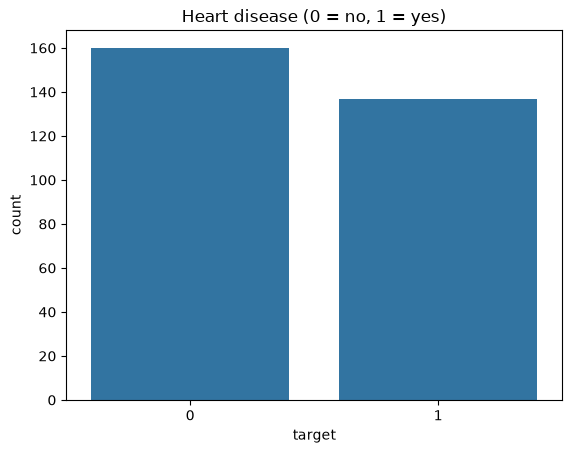

In [9]:
print(raw["target"].value_counts().sort_index())

df = pd.read_csv("../data/dataset.csv")
print(df.shape)
print(df["target"].value_counts(normalize=True))

sns.countplot(x="target", data=df)
plt.title("Heart disease (0 = no, 1 = yes)")
plt.show()

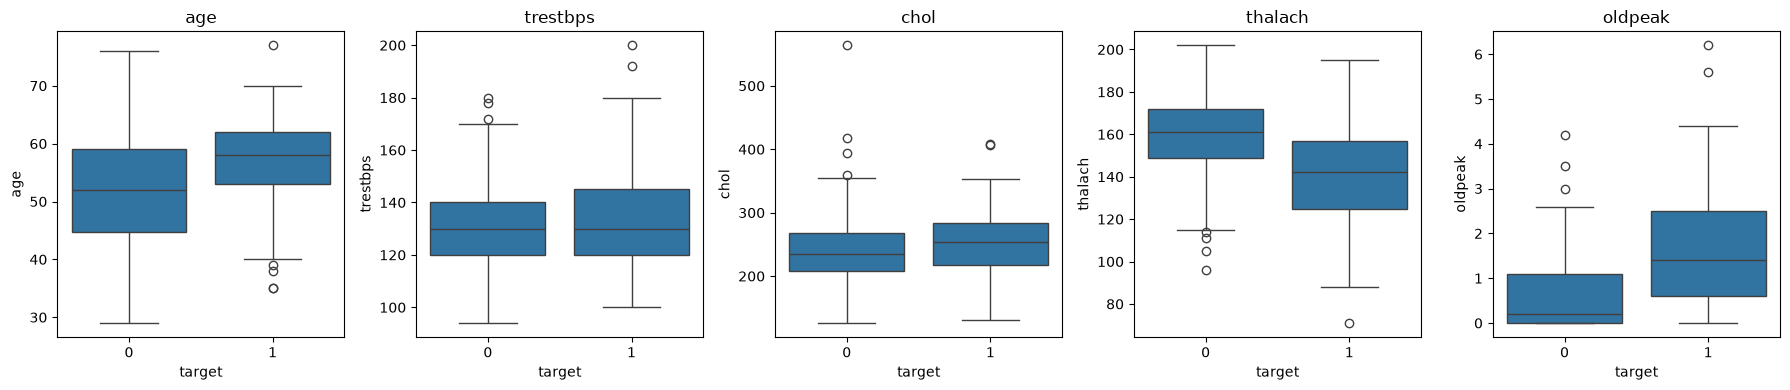

In [11]:
numeric_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x='target', y=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

subplots(1, 5) makes five charts in a row, and zip(axes, numeric_cols) pairs each chart with one column.
Each boxplot compares the feature for target 0 and target 1. Look for features where the two boxes barely overlap. Those separate the classes best. You should see thalach lower and oldpeak higher in the disease group.

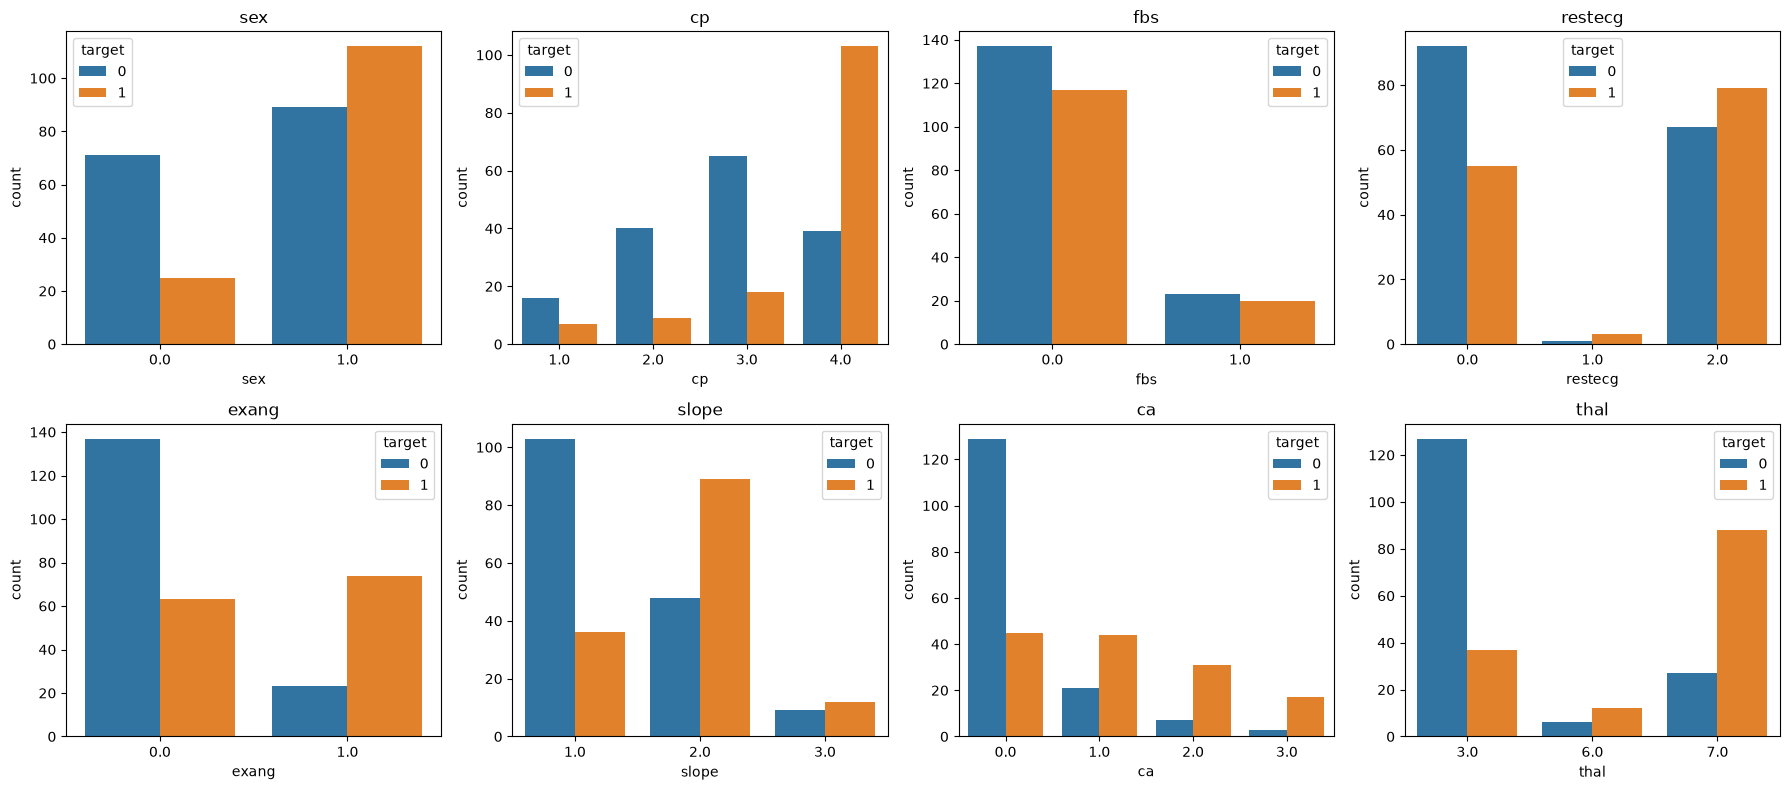

In [12]:
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), cat_cols):
    sns.countplot(x=col, hue='target', data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

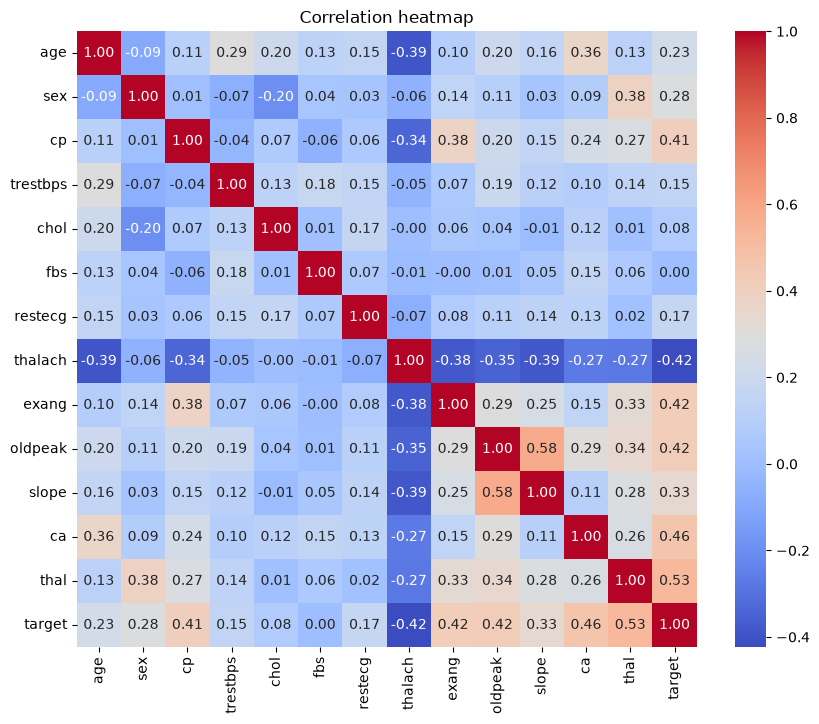

In [13]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

In [ ]:
import sys
print(sys.executable)

c:\Python314\python.exe
